# 3.1 · A multi-factor long-short strategy

**Hypothesis:** stocks with certain characteristics (*factors*) have historically earned higher returns than others,
a cross-sectional pattern documented in the asset-pricing literature (Fama-French, Carhart, Asness et al.). A
**long-short** portfolio buys the stocks that score best and *sells short* those that score worst. If the spread
between them is positive, the portfolio earns it **largely independent of the market's direction**: its return is
close to the factor premium alone.

**Short selling:** borrowing a share, selling it, and buying it back later to return to the lender. The short seller
gains if the price falls and loses if it rises, and pays a borrowing fee meanwhile.

| Factor | Economic intuition | Measurement |
|---|---|---|
| **Value** | cheap stocks earn a premium (risk compensation or investor over-extrapolation) | earnings, sales, book value and operating profit relative to market capitalisation |
| **Quality** | profitable, conservatively financed firms are under-priced | return on equity and on invested capital, gross profit to assets, low leverage |
| **Momentum** | past 12-month winners keep outperforming for some months (under-reaction) | the return over the past 12 months excluding the most recent month (to avoid short-term reversal) |
| **Low volatility** | low-risk stocks earn more risk-adjusted return than the CAPM predicts | low standard deviation of daily returns over the past year |

Each factor is standardised cross-sectionally into a **z-score** per stock and month, $z_i = (x_i - \bar{x}) / s_x$,
and the four z-scores are averaged into one **composite score** (a weighted mean: the weights are a parameter,
`FACTOR_WEIGHTS` in the first code cell, equal by default).

**Portfolio rules** (every setting is recorded in the configuration below):

* **Universe:** the S&P 1500 constituents (S&P 500 + 400 + 600) *as of each date* - never today's list applied to the
  past, which would introduce survivorship bias.
* **Monthly rebalance:** long the top decile by composite score, short the bottom decile. A position already held is
  kept until it leaves the top (bottom) quintile - a *buffer* that reduces turnover from names oscillating around the
  cut-off.
* **Beta-neutral:** each side is scaled so that the portfolio's market beta is zero; high-beta stocks get smaller
  positions, so market moves cancel between the two legs.
* **Transaction costs:** every trade pays 0.10 % for large caps rising to 0.50 % for small caps, and every short pays
  a borrowing fee. All results below are *net* of costs.
* **Point-in-time:** each rebalance uses only prices and statements published before that date.

In [1]:
from dataclasses import replace

import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.db.engine import get_engine
from equity_research.research.cache import ResearchCache
from equity_research.research.indices import calendar_years, tracking, vendor_returns
from equity_research.research.registry import HoldoutClosedError, deflated_sharpe
from equity_research.research.strategy import StrategyConfig, run_strategy

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
TODAY = pd.Timestamp.today().strftime("%Y-%m-%d")

engine = get_engine()
# The composite score is the weighted mean of these factors' z-scores. Only the ratios matter, and any factor
# run_strategy knows can be added (its error lists them). Equal weights are the notebook's registered trials; any
# change is a new trial, so choose the weights before seeing the results.
FACTOR_WEIGHTS = {"value": 1.0, "quality": 1.0, "momentum": 1.0, "low_vol": 1.0}
config = StrategyConfig(
    family="multi_factor_ls",
    universe="SP1500",
    start="2010-01-01",
    end="2024-12-31",
    factors=tuple(FACTOR_WEIGHTS.items()),
    enter=0.10,
    exit_=0.20,
    long_only=False,
    beta_neutral=True,
)
result = run_strategy(cache, config, engine=engine)
print("Registered as research run", result.run_id)

left out 887 facts of 2 companies in ['GBP']


Registered as research run 113


## Performance

,value,meaning
cagr,0.06267,average growth per year
vol,0.1619,typical yearly ups and downs
sharpe,0.4575,return per unit of risk
max_drawdown,-0.473,worst fall from a high
turnover,6.993,times the book is traded per year
beta,-0.02875,NaN
alpha,0.07421,NaN
active_return,-0.0678,NaN
tracking_error,0.2038,NaN
information_ratio,-0.3555,NaN


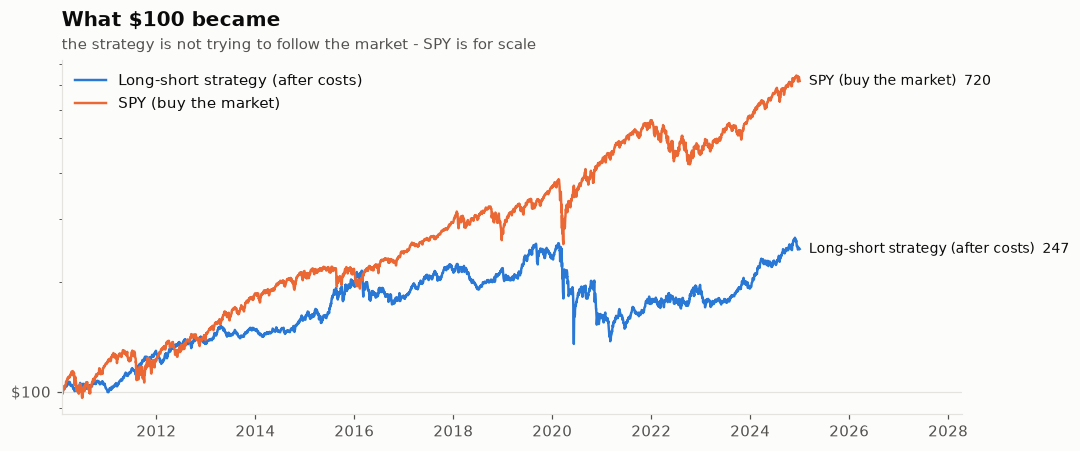

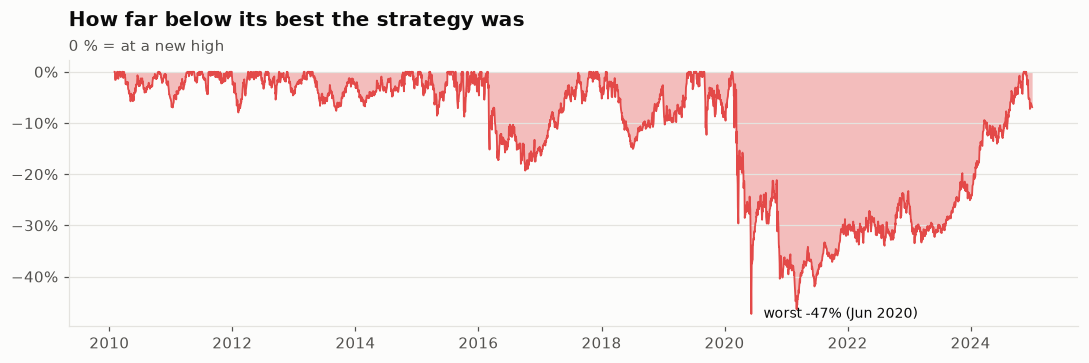

In [2]:
MEANING = {
    "cagr": "average growth per year",
    "vol": "typical yearly ups and downs",
    "sharpe": "return per unit of risk",
    "max_drawdown": "worst fall from a high",
    "turnover": "times the book is traded per year",
    "trials": "versions of this idea tried so far",
    "deflated_sharpe": "chance the result is real, not luck",
}
metrics = pd.DataFrame({"value": result.metrics}).assign(meaning=lambda d: d.index.map(MEANING))
display(metrics)
spy = vendor_returns(cache, "SPY", total=True)
net = result.backtest.net[result.backtest.net.index >= pd.Timestamp(config.start)]
fig = charts.growth(
    {"Long-short strategy (after costs)": net, "SPY (buy the market)": spy},
    "What $100 became",
    subtitle="the strategy is not trying to follow the market - SPY is for scale",
)
fig = charts.drawdown(net, "How far below its best the strategy was", subtitle="0 % = at a new high")

Calendar-year returns. A beta-neutral book should show little correlation with the market: it can gain in a year the
market falls, and lag in a year it rallies.

Market sensitivity (beta to SPY): 0.23  - near 0 is what beta-neutral aims for


,Strategy,SPY
trade_date,,
2010,1.3%,19.4%
2011,26.7%,1.9%
2012,5.6%,16.0%
2013,9.3%,32.3%
2014,6.6%,13.5%
2015,25.8%,1.3%
2016,-7.8%,12.0%
2017,18.3%,21.7%
2018,1.0%,-4.6%


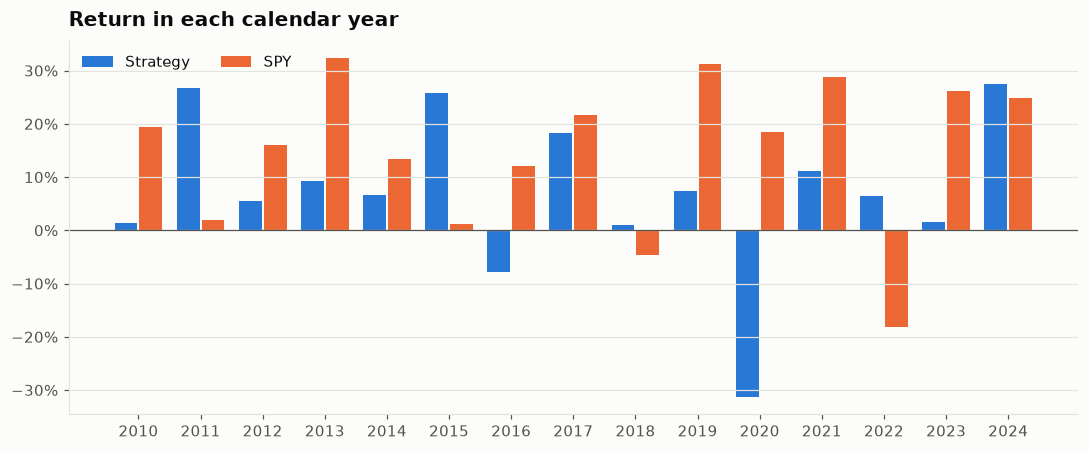

In [3]:
years = calendar_years({"Strategy": net, "SPY": spy})
fig = charts.yearly_bars(years, "Return in each calendar year")
print(f"Market sensitivity (beta to SPY): {tracking(net, spy)['beta']:.2f}  - near 0 is what beta-neutral aims for")
display(years.style.format("{:.1%}"))

## Factor attribution

The same portfolio built on one factor at a time. Each run is a separate *trial* of the hypothesis "single-factor
long-short" and is registered like the first, so the multiple-testing correction below counts it.

In [4]:
singles = {}
for name in FACTOR_WEIGHTS:
    one = run_strategy(cache, replace(config, family="single_factor_ls", factors=((name, 1.0),)), engine=engine)
    singles[name] = one.metrics
singles["all four"] = result.metrics
display(
    pd.DataFrame(singles)
    .T[["cagr", "vol", "sharpe", "max_drawdown", "turnover"]]
    .style.format(
        {"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}", "turnover": "{:.1f}"}
    )
)

left out 887 facts of 2 companies in ['GBP']
left out 887 facts of 2 companies in ['GBP']
left out 887 facts of 2 companies in ['GBP']
left out 887 facts of 2 companies in ['GBP']


,cagr,vol,sharpe,max_drawdown,turnover
value,-3.5%,14.5%,-0.17,-63%,4.4
quality,5.6%,11.1%,0.55,-25%,4.0
momentum,0.7%,18.4%,0.13,-49%,9.3
low_vol,8.2%,23.5%,0.46,-66%,4.7
all four,6.3%,16.2%,0.46,-47%,7.0


The composite is usually less volatile than any single factor: factor returns are imperfectly (sometimes negatively)
correlated, so combining them diversifies - value and momentum are the classic negatively correlated pair.

## Robustness to the data vendor

A result that depends on one vendor's data is fragile. Here the same portfolio is built from **LSEG's** financial
statements instead of the SEC's - one setting changes, the code does not. (LSEG keeps restated figures while the SEC
data keeps the first-reported ones, so small differences are expected.)

left out 887 facts of 2 companies in ['GBP']


,cagr,vol,sharpe,max_drawdown,turnover
SEC accounts,0.06267,0.1619,0.4575,-0.473,6.993
LSEG accounts,0.06415,0.1637,0.4626,-0.4629,7.01


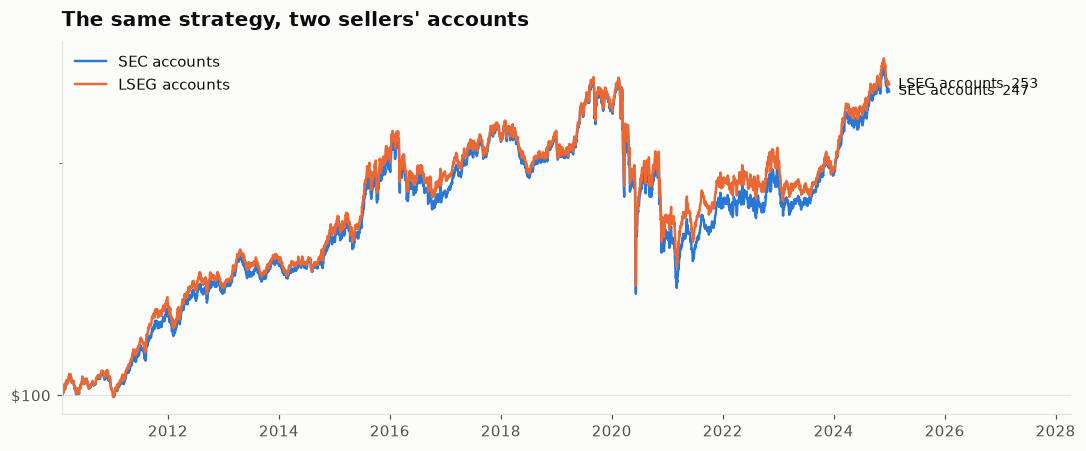

In [5]:
lseg_accounts = run_strategy(cache, replace(config, fundamentals_vendor="refinitiv"), engine=engine)
both = pd.DataFrame({"SEC accounts": result.metrics, "LSEG accounts": lseg_accounts.metrics}).T
display(both[["cagr", "vol", "sharpe", "max_drawdown", "turnover"]])
fig = charts.growth(
    {"SEC accounts": result.backtest.net, "LSEG accounts": lseg_accounts.backtest.net},
    "The same strategy, two sellers' accounts",
)

## Multiple testing and the deflated Sharpe ratio

Test enough strategy variants and one will look excellent by chance alone: the maximum of many noisy Sharpe ratios is
biased upwards, even when every true Sharpe ratio is zero (the *backtest overfitting* problem). So every backtest run
through `run_strategy` is recorded in `research.run`, grouped by *family* (one research hypothesis).

The **deflated Sharpe ratio** (Bailey and López de Prado, 2014) is the probability that the true Sharpe ratio is
positive, after adjusting the benchmark Sharpe for the number of trials in the family and for the non-normality
(skewness and kurtosis) of the returns. Above 0.95 is evidence of skill at the usual 5 % level; 0.5 is no evidence
either way.

The same observed Sharpe ratio becomes less convincing as the number of trials grows:

In [6]:
r = result.backtest.net.dropna()
sharpe, n = float(result.metrics["sharpe"]), len(r)
display(
    pd.Series(
        {trials: deflated_sharpe(sharpe=sharpe, trials=trials, observations=n) for trials in (1, 5, 10, 30, 100)},
        name=f"chance it is real (Sharpe {sharpe:.2f})",
    )
    .rename_axis("versions tried")
    .to_frame()
    .style.format("{:.1%}")
)

,chance it is real (Sharpe 0.46)
versions tried,
1,96.1%
5,71.7%
10,57.6%
30,37.9%
100,22.2%


## The hold-out period

The years from 2025 on are an **out-of-sample hold-out**: no backtest may use them during development, so they cannot
influence design choices. Only a final, chosen strategy is evaluated on them, once. Reusing a hold-out repeatedly
turns it into in-sample data. A request for it now is refused:

In [7]:
try:
    run_strategy(cache, replace(config, end=TODAY), engine=engine)
except HoldoutClosedError as refused:
    print("Refused:", refused)

Refused: the backtest ends 2026-11-06, inside the hold-out from 2025-01-01: end it before, or open the hold-out explicitly (only for a final strategy)


## Glossary

* **Factor** - a measurable stock characteristic associated with differences in expected returns.
* **z-score** - a value's distance from the cross-sectional mean in standard deviations; 0 is average.
* **Rebalance** - the date the portfolio is traded back to its target holdings (here: every month end).
* **Turnover** - the fraction of the portfolio traded per year; 3.0 means the whole book is replaced three times.
* **Sharpe ratio** - annualised excess return divided by annualised volatility: return per unit of total risk. For an
  equity strategy, above 0.5 is respectable and above 1 is strong.
* **Beta** - the sensitivity of a portfolio's return to the market's, from a regression of one on the other.
* **Maximum drawdown** - the largest peak-to-trough decline (the deepest point of the drawdown chart).
* **Hold-out** - the most recent years, reserved for a single out-of-sample test.

**Next:** notebook 3.2 builds a long-only version that an investor who cannot short could hold.